# THP — Data Engineer II Technical Exercise

In [65]:
from pathlib import Path
import sqlite3
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# Project directory
BASE_DIR = Path.cwd().resolve()

# Database path
DB_PATH = BASE_DIR/"database"/"schema.db"

# Verify database exists
assert DB_PATH.exists(), f"Database not found: {DB_PATH}"

connection = sqlite3.connect(DB_PATH)
print("Connection successful.")

def run_query(sql, params=None):
    # Run query in code chunks later
    with get_connection() as conn:
        return pd.read_sql_query(
            sql,
            conn,
            params=params
        )

Connection successful.


# 1. Does Jeopardy increasingly favor certain areas of knowledge?

Put differently: As the public eye focuses on different fields of study, does Jeopardy also change focus?

Context: Contestants are generally expected by viewer audiences to have an extremely wide base of knowledge, where any subject or category is fair game. In reality, the show favors short-form knowledge up to the level of high school or undergraduate colleges, in order to allow viewers chances to engage and answer even if not watching episodes continuously.

In [66]:
query1 = """
    SELECT
        cd.season,
        cl.category,
        COUNT(*) AS clue_count,
        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (PARTITION BY cd.season),
            2
        ) AS category_percentage
    FROM clue_data AS cl
    JOIN contest_data AS cd
        ON cl.air_date = cd.air_date
    GROUP BY
        cd.season,
        cl.category
    ORDER BY
        cd.season,
        category_percentage DESC;
"""

category_df = pd.read_sql_query(query1, connection)

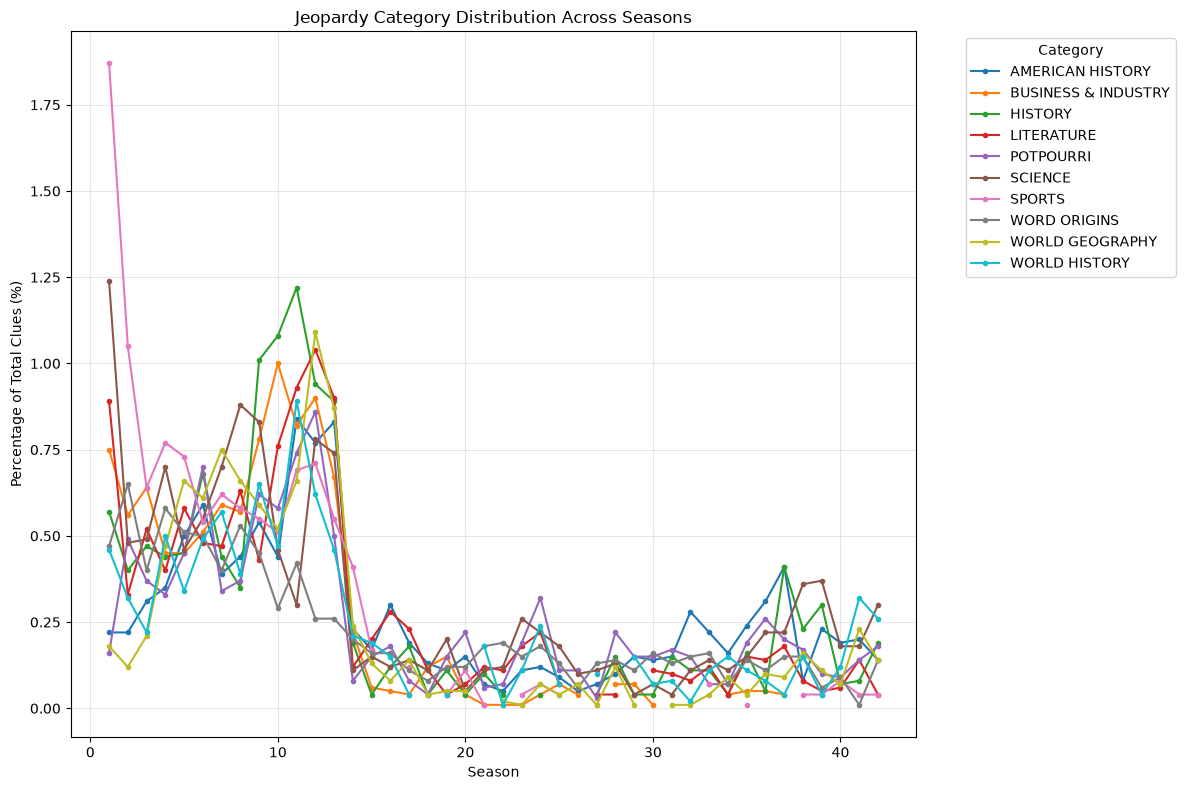

In [84]:
# Get 10 most common categories
top_categories = (
    category_df.groupby("category")["clue_count"]
    .sum()
    .nlargest(10)
    .index
)

# Keep only those categories in final table
plot_df = category_df[
    category_df["category"].isin(top_categories)
]

# Reshape table for plotting
plot_data = plot_df.pivot(
    index="season",
    columns="category",
    values="category_percentage"
)

# Create line chart
plt.figure(figsize=(12, 8))

for category in plot_data.columns:
    plt.plot(
        plot_data.index,
        plot_data[category],
        label=category,
        marker="o",
        markersize=3
    )

plt.title("Jeopardy Category Distribution Across Seasons")
plt.xlabel("Season")
plt.ylabel("Percentage of Total Clues (%)")
plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Overall, the show has maintained a steady flow of its most popular subjects (also, every other category is arguably simply an offshoot of the top 10 or 20 subjects). Up to season 15, the show experimented with categories.

Notably, the show has increased both its specificity in naming categories and its equalization of categories:
- What may have appeared as 'Sports' in an earlier time now will likely have a highly specific word or phrase, often a wordplay or pun, to denote what the category contains.
- The show appears to randomize the categories used per season in order to keep competitors guessing, to the point where certain broad categories don't actually appear in occasional seasons.

# 2. What is the relationship between performance in earlier  and later rounds?

Put differently: Can a consistent competitor dominate, or can weaker competitors catch up?

Context: Given that Jeopardy questions only increase in value over time until Final Jeopardy, a natural assumption could be that the first round doesn't matter as much, and that it is better to focus on the slightly more esoteric knowledge of Double Jeopardy.

In [74]:
# Compare average contestant scores at the end of Single, Double, and Final Jeopardy
query2 = """
    SELECT
        'Single Jeopardy' AS Round,
        ROUND(AVG(score), 2) AS 'Average Score',
        ROUND(AVG(CASE WHEN score != 0 THEN score END), 2)
            AS 'Zeroes Removed'
    FROM (
        SELECT single_left AS score FROM contest_data
        UNION ALL
        SELECT single_middle FROM contest_data
        UNION ALL
        SELECT single_right FROM contest_data
    )
    
    UNION ALL
    
    SELECT
        'Double Jeopardy',
        ROUND(AVG(score), 2),
        ROUND(AVG(CASE WHEN score != 0 THEN score END), 2)
    FROM (
        SELECT double_left AS score FROM contest_data
        UNION ALL
        SELECT double_middle FROM contest_data
        UNION ALL
        SELECT double_right FROM contest_data
    )
    
    UNION ALL
    
    SELECT
        'Final Jeopardy',
        ROUND(AVG(score), 2),
        ROUND(AVG(CASE WHEN score != 0 THEN score END), 2)
    FROM (
        SELECT final_left AS score FROM contest_data
        UNION ALL
        SELECT final_middle FROM contest_data
        UNION ALL
        SELECT final_right FROM contest_data
    );
"""

pd.read_sql_query(query2, connection, index_col = None)

,Round,Average Score,Zeroes Removed
0,Single Jeopardy,3355.15,3384.40
1,Double Jeopardy,9275.91,9303.81
2,Final Jeopardy,9488.31,10291.16


Given the ratio between Single and Double Jeopardy, roughly 1 to 3, it is likely that:
- Performance doesn't increase drastically between rounds even when monetary value does; a competitor will give fewer correct answers in Double Jeopardy, indicating a clear margin in difficulty.
- Performance has been clearly modulated between the two rounds, where a comptitor will likely triple their score in proper proportion to the overall value of the round.
- Single Jeopardy is substantive and valuable as a round; a competitor cannot ignore the round in favor of attempting to dominate Double Jeopardy.

# 3. Are episodes and contestants becoming more competitive over time?

Put differently: Has Jeopardy reached a wide enough audience to produce a vast pool of equally strong competitors, or do single competitors still stand out?

Context: As Jeopardy has gained popularity, the level of interest from strong academics has also increased. Furthermore, Jeopardy competitors now have access to the Internet as well as decades of strategies written by top competitors. Similar to chess, a Jeopardy competitor can quickly become familiar with the content, but might not necessarily succeed at the highest level.

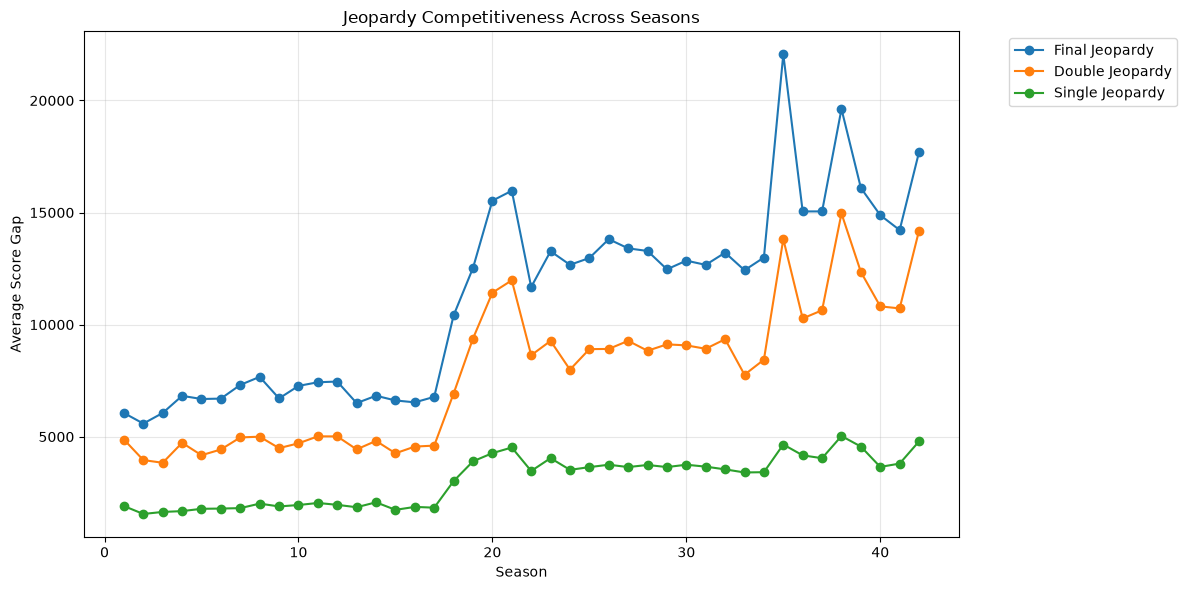

In [91]:
query3 = """
SELECT
    season,
    air_date,
    single_left, single_middle, single_right,
    double_left, double_middle, double_right,
    final_left, final_middle, final_right
FROM contest_data
"""

df = pd.read_sql_query(query3, connection)

In [ ]:
# Calculate average score gaps for each game and round
def competitiveness_gap(scores):
    scores = sorted(scores, reverse=True)

    first_second = scores[0] - scores[1]
    first_third = scores[0] - scores[2]

    return (first_second + first_third) / 2

for round_name in ["single", "double", "final"]:
    df[f"{round_name}_gap"] = df.apply(
        lambda row: competitiveness_gap([
            row[f"{round_name}_left"],
            row[f"{round_name}_middle"],
            row[f"{round_name}_right"]
        ]),
        axis=1
    )

# Calculate average gaps by season
season_gaps = (
    df.groupby("season")[
        ["single_gap", "double_gap", "final_gap"]
    ]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    season_gaps["season"],
    season_gaps["final_gap"],
    marker="o",
    label="Final Jeopardy"
)

plt.plot(
    season_gaps["season"],
    season_gaps["double_gap"],
    marker="o",
    label="Double Jeopardy"
)

plt.plot(
    season_gaps["season"],
    season_gaps["single_gap"],
    marker="o",
    label="Single Jeopardy"
)

plt.title("Jeopardy Competitiveness Across Seasons")
plt.xlabel("Season")
plt.ylabel("Average Score Gap")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Notably, Season 18 introduced doubled money dollar values, explaining the massive spread increase. Overall, however, the plot shows consistent increase per round; due to uniform question difficulty, a competitor cannot shoot ahead in points in later rounds.  Any marked increases in the average gap between scores can be attributed to the appearance of an unusually capable competitor or a season's change in the relative difficulty of its questions.

# 4. Are higher-value clues associated with specific categories?

Put differently: Can a competitor focus on building a narrower but deeper knowledge base?

Context: Jeopardy is known for certain questions that are "gimmes", i.e. automatic; for example, most contestants agree on the benefit of familiarity with important leaders & years in world history. However, maintaining familiarity with sports, literature, biology, chemistry, geography, geology, and more on top of that causes many contestants to struggle.

In [70]:
query4 = """
SELECT
    category,
    clue_value
FROM clue_data
WHERE clue_value IS NOT NULL
  AND clue_value > 0
  AND round IN (1, 2)
"""

df = pd.read_sql_query(query4, connection)

In [75]:
# Remove categories with fewer than 10 clues
category_counts = df["category"].value_counts()

df = df[
    df["category"].isin(
        category_counts[category_counts >= 10].index
    )
]

# Calculate average clue value by category and round
category_values = (
    df.groupby(["category"])["clue_value"]
    .agg(["mean"])
    .reset_index()
)

category_values["mean"] = category_values["mean"].round(0)

# Display categories with the highest average clue values
category_values.sort_values("mean", ascending=False, ignore_index = True).head(10)

,category,mean
0,CHAMBER MUSIC,1300.0
1,A ROUND OF GULF,1292.0
2,CELEBRITY POLITICIANS,1273.0
3,ALBUM COVERS,1267.0
4,PROLOGUES,1267.0
5,"ART ""C\""",1262.0
6,HOW NOVEL!,1257.0
7,ART SUBJECTS,1257.0
8,20th CENTURY BOOKS,1257.0
9,SPACE SCIENCE,1257.0


Assuming the subject has more than 10 clues (2 appearances in the show), the most "expensive" subjects are typically esoteric offshoots of common categories. Here, literature is the most common borad subject, followed by science, art, and geography. Notably, more random questions appear in Single Jeopardy, and more academic-minded questions appear in Double Jeopardy; apart from this, there is likely little reason to aim for a win by specifically dominating a certain category or set of categories.

# 5. Does having the highest Coryat score predict winning?

Put differently: Does the contestant with the most knowledge always win? How strong is the effect of wagering and Final Jeopardy?

Context: many contestants emphasize two factors in addition to knowledge preparation: (1) being able to wager accurately and strategically, and (2) being able to buzz in correctly and accurately. Assuming that most contestants are human and have a timing and reaction speed of 200 ms ± 80, clever wagering becomes the linchpin for performances that can control or overturn the game. One commonly understood strategy is that it is better to risk getting Final Jeopardy wrong than to bet lower than a trailing player and both get it right; the trailing player has a lower maximum to bet despite a potentially equal knowledge base.

In [62]:
query5 = """
SELECT
    season,
    air_date,
    name_left, name_middle, name_right,
    coryat_left, coryat_middle, coryat_right,
    double_left, double_middle, double_right,
    final_left, final_middle, final_right
FROM contest_data
"""

df = pd.read_sql_query(query5, connection)

In [63]:
# Reshape contestant data into individual observations
contestants = []

for _, row in df.iterrows():
    for position in ["left", "middle", "right"]:
        contestants.append({
            "season": row["season"],
            "air_date": row["air_date"],
            "position": position,
            "name": row[f"name_{position}"],
            "coryat": row[f"coryat_{position}"],
            "double_score": row[f"double_{position}"],
            "final_score": row[f"final_{position}"]
        })

contestants_df = pd.DataFrame(contestants)

# Identify Coryat leader and actual winner in each game
results = []

for air_date, game in contestants_df.groupby("air_date"):
    game = game.dropna(
        subset=["coryat", "final_score"]
    )

    if len(game) != 3:
        continue

    coryat_leader = game.loc[game["coryat"].idxmax()]
    winner = game.loc[game["final_score"].idxmax()]

    # Require a unique Coryat leader and outright winner
    if (game["coryat"] == coryat_leader["coryat"]).sum() > 1:
        continue

    if (game["final_score"] == winner["final_score"]).sum() > 1:
        continue

    results.append({
        "season": coryat_leader["season"],
        "coryat_leader": coryat_leader["name"],
        "coryat_score": coryat_leader["coryat"],
        "final_score": coryat_leader["final_score"],
        "score_change": (
            coryat_leader["final_score"]
            - coryat_leader["double_score"]
        ),
        "final_placement": (
            1 if coryat_leader["name"] == winner["name"]
            else game["final_score"].rank(
                ascending=False, method="min"
            ).loc[coryat_leader.name]
        ),
        "won": coryat_leader["name"] == winner["name"]
    })

results_df = pd.DataFrame(results)

# Calculate overall winning percentage
winning_percentage = results_df["won"].mean() * 100
score_change = results_df["score_change"].mean().round(2)

print(f"Games analyzed: {len(results_df)}")
print(f"Coryat leaders who won outright: {winning_percentage:.2f}%")
print(f"Average score change for Coryat leaders: {score_change:.0f}")

Games analyzed: 9148
Coryat leaders who won outright: 71.50%
Average score change for Coryat leaders: 559


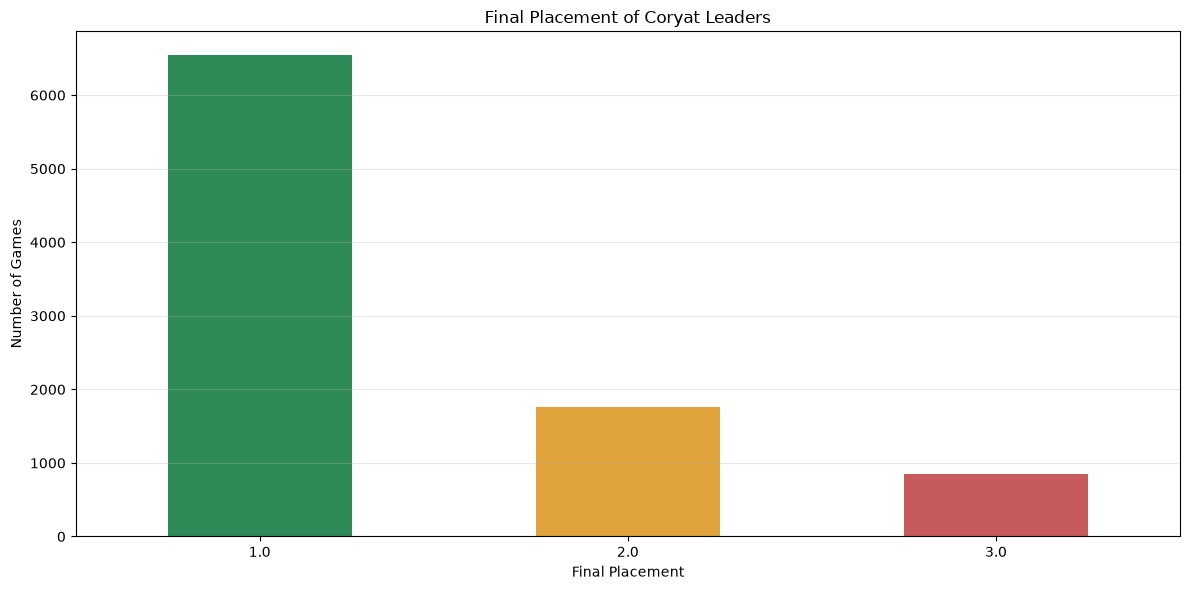

In [85]:
# Count final placements
placement_counts = (
    results_df["final_placement"]
    .value_counts()
    .sort_index()
)

placement_counts.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#2E8B57", "#E0A23B", "#C75B5B"]
)

plt.title("Final Placement of Coryat Leaders")
plt.xlabel("Final Placement")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Generally speaking, the person with the highest Coryat score during the game will in fact be the eventual victor; assuming all other factors are equal, their skill in answering Final Jeopardy and wagering money will often be a match to their fellow competitors'. Also, any upsets will be caused by massive wagers rather than severe gaps in knowledge, as evidenced by the low average score change (again, the idea is to wager a safe amount to stay ahead of the 2nd-place competitor).